# Assignment 4: Image Classification

In this assignment, you will classify images using the [**Darknet framework**](https://darknetcv.ai/api/). You will use OpenCV library and the [**DNN module**](https://docs.opencv.org/4.x/d2/d58/tutorial_table_of_content_dnn.html), which are very fast due to the optimizations inherent in the OpenCV library.

**Step 1: Learning- Classifying one image**

1. Familiarze yourself with popular pre-trained models
2. Learn how to load and apply an image classification model
3. Experiment with the model using additional image examples

**Step 2: Assignment- Classifying Several Images**


## Step 1: Learning - Background

### **Popular pre-trained models**

The OpenCV supports many [**state-of-the-art models**](https://github.com/opencv/opencv/wiki/Deep-Learning-in-OpenCV) including YOLO, TensorFlow, PyTorch, and Caffee. [**This github repo**](https://github.com/opencv/opencv/tree/master/samples/dnn) contains several sample code for several models.

### **Frameworks**

Some popular deep learning frameworks:

*  **Caffe**

You can use the following function to read a network model stored in Caffe framework's format **`readNetFromCaffe()`**. More info here [**`cv2.dnn.readNetFromCaffe()`**](https://docs.opencv.org/4.5.2/d6/d0f/group__dnn.html#ga29d0ea5e52b1d1a6c2681e3f7d68473a)

*  **TensorFlow**

You can use the following function to read a network model stored in [TensorFlow](https://www.tensorflow.org/) framework's format:
**`readNetFromTensorflow()`**. More info here [**`cv2.dnn.readNetFromTensorflow()`**](https://docs.opencv.org/4.5.2/d6/d0f/group__dnn.html#gad820b280978d06773234ba6841e77e8d)

*  **Torch and PyTorch**

For loading Torch model files, we need the file containing the pre-trained weights. Generally, this file has a `.t7` or `.net` extension.

You can use the following function to read a network model stored in [Torch7](http://torch.ch/) framework's format **`readNetFromTorch()`**. More info here [**`cv2.dnn.readNetFromTorch()`**](https://docs.opencv.org/4.5.2/d6/d0f/group__dnn.html#ga65a1da76cb7d6852bdf7abbd96f19084)

*  **Darknet**

You can use the following function to read a network model stored in [Darknet](https://pjreddie.com/darknet/) model files: **`readNetFromDarknet()`**. More info here [**`cv2.dnn.readNetFromDarknet()`**](https://docs.opencv.org/3.4/d6/d0f/group__dnn.html#gafde362956af949cce087f3f25c6aff0d)

*  **Reading any DNN model**

You can use the following function to read deep learning network in any supported format and returns a `Net` object **`readNet()`**. More info here [**`cv2.dnn.readNet()`**](https://docs.opencv.org/4.5.2/d6/d0f/group__dnn.html#ga3b34fe7a29494a6a4295c169a7d32422)

## Image Classification using DNN

For this assignment, you will implement one of the most common computer vision problems using the DNN module. You will use the [**DenseNet121**](https://huggingface.co/qualcomm/DenseNet-121) deep neural network model for classifying images into 1000 classes of [*ImageNet*](https://www.google.com/url?sa=t&rct=j&q=&esrc=s&source=web&cd=&cad=rja&uact=8&ved=2ahUKEwjasLG-yKbyAhW3IbcAHRW1BZkQFnoECAwQAw&url=https%3A%2F%2Fwww.image-net.org%2F&usg=AOvVaw07SoUbpxRQk8ZNEiJoLqt5) dataset.

* The model DenseNet-121 full python code can be found [*here*](https://github.com/pytorch/vision/blob/main/torchvision/models/densenet.py)

* Pretrained DenseNet Models on ImageNet [*DenseNet-Caffee*](https://github.com/shicai/DenseNet-Caffe)


To classify an image, you will go through the following process:

1. Read the class labels from a .txt file – This file contains the names of all the objects the model can recognize.
2. Load the pre-trained neural network using `readNet` function to import the model from disk.
3. Import the input image you want to classify.
4. Convert the image into a blob using `blobFromImage` function.
5. Use the function `setInput` to feed the blob into the network.
6. Run the model to get predictions (`forward`)


In [1]:
#Import the libraries
import cv2
import numpy as np
import glob
import matplotlib.pyplot as plt
%matplotlib inline

# 1. Read the ImageNet class names from the input folder (classification_classes_ILSVRC2012.txt')
with open('../input/classification_classes_ILSVRC2012.txt', 'r') as f:
    image_net_names = f.read().split('\n')

# Save all available classification labels, excluding the empty line at the end.
class_names = image_net_names[:-1]

# Verify the size, and inspect one of the classes by name.
print(len(class_names), class_names[100])

1000 black swan, Cygnus atratus


In [2]:
# 2. Loading the Classification model (caffe) using readNet function.
config_file = '../models/DenseNet_121.prototxt'
model_file = '../models/DenseNet_121.caffemodel'

model = cv2.dnn.readNet(model=model_file, config=config_file, framework='Caffe')

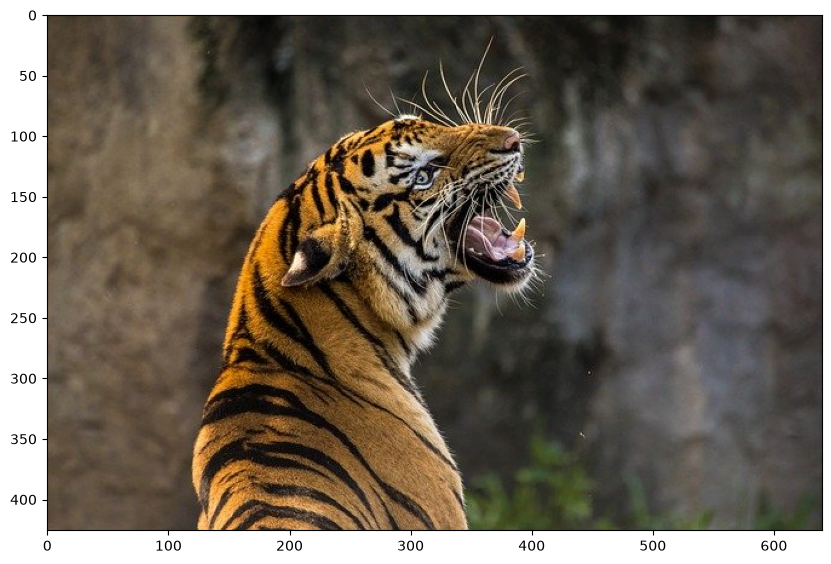

In [3]:
# 3. Import the image you want to classify.
tiger_img = cv2.imread('../input/image1.jpg')
plt.figure(figsize=[10, 10])
plt.imshow(tiger_img[:, :, ::-1]);

4. Convert the image into a blob.

The blob speficications are given at the top of in `DenseNet_121.prototxt`:
```
name: "DENSENET_121"
input: "data"
input_dim: 1  -- Number of images per blob
input_dim: 3   --- Number of channels per image (full color, no alpha)
input_dim: 224   ---(height)
input_dim: 224    ---(width)
```

The mean and scalefactor to use also come from the model itself ([see here](https://github.com/shicai/DenseNet-Caffe)).

In [4]:
# 4. Convert the image into a blob. The blob specifications are found in DenseNet_121.prototxt.
blob = cv2.dnn.blobFromImage(
    image=tiger_img, scalefactor=0.017, size=(224, 224), mean=(104, 117, 123), swapRB=False, crop=False)

In [5]:
# 5. Set the input blob for the neural network.
model.setInput(blob)

In [6]:
# 6. Forward the blob through the network.
outputs = model.forward()
final_outputs = outputs[0]

In [7]:
# Make all the outputs 1D, where each represents likihood of matching one of the 1K classification groups.
final_outputs = final_outputs.reshape(1000, 1)

# Get the class label index with the max confidence.
label_id = np.argmax(final_outputs)

# Convert score to probabilities for all matches.
probs = np.exp(final_outputs) / np.sum(np.exp(final_outputs))

print(probs[:10])
print("Max probability:", np.max(probs))

[[2.1499585e-10]
 [4.0102185e-10]
 [4.2768603e-10]
 [3.2427311e-10]
 [1.6526440e-11]
 [1.6457802e-11]
 [1.5199699e-11]
 [4.4728012e-09]
 [5.0410884e-09]
 [1.1915433e-09]]
Max probability: 0.9372195


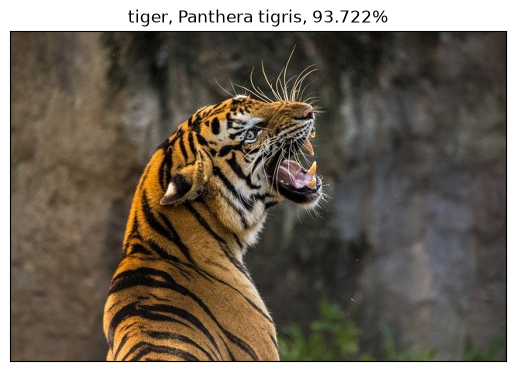

In [8]:
# Get the final highest probability
final_prob = np.max(probs) * 100.0

# Map the max confidence to the class label names.
out_name = class_names[label_id]
out_text = f"{out_name}, {final_prob:.3f}%"

# Display the image, best matched classification, and confidence.
plt.imshow(tiger_img[:, :, ::-1])
plt.title(out_text)
plt.xticks([]), plt.yticks([])
plt.show() 

# Step 2- Assignment: classifying several images

Now that you have successfully implemented Image classification workflow, it's time to apply the model to multiple examples and create a reusable function for batch processing.

We can now give a try at applying the model to more examples. To more neatly use our workflow, we have defined the prios steps into the below reusable function.
Now let us use this function to classify a whole folder of images. Feel free to drop in some of your own jpg images into the `input` folder if you want to see what the model comes up with.


## Part 2 Setting up

Everything from step 1 is reused here. The class names are already in `class_names` and the
network is already in `model`, so the two loading steps are not repeated for every picture. A
DenseNet caffemodel is 32 MB on disk and reading it again for each image would take far longer
than the classification itself.

One practical note before anything runs. The Caffe reader was removed from OpenCV in version 5,
so `cv2.dnn.readNet` in the cell above only works on OpenCV 4. The version this notebook was run
with is printed below.

In [9]:
# Extra imports and a plotting style for this part
import os
import time
import shutil
import pandas as pd

print("OpenCV version:", cv2.__version__)

# Colours. One blue for a single line of numbers and three steps of the same blue for the
# first, second and third guess, so that rank is readable without a legend.
ACCENT = "#2a78d6"
RANK_COLOURS = ["#1c5cab", "#3987e5", "#86b6ef"]
INK = "#111111"
INK_SOFT = "#555555"
WARN = "#e34948"

plt.rcParams.update({
    "figure.facecolor": "#ffffff",
    "axes.facecolor": "#ffffff",
    "axes.edgecolor": "#cccccc",
    "axes.labelcolor": INK_SOFT,
    "axes.titlecolor": INK,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#dddddd",
    "grid.linewidth": 0.8,
    "text.color": INK,
    "xtick.color": INK_SOFT,
    "ytick.color": INK_SOFT,
    "font.size": 10,
    "figure.dpi": 110,
})


def short(label):
    """ImageNet gives every class a list of synonyms. The first one is the everyday name."""
    return label.split(",")[0].strip()


def class_index(name):
    """Find the position of a class from its everyday name, used to follow one class in a test."""
    for i, full in enumerate(class_names):
        if short(full) == name:
            return i
    raise ValueError(f"no class called {name}")


print("Ready")

OpenCV version: 4.14.0
Ready


### 1 The reusable function

`classify_image` holds the working part of the six steps from step 1. It takes either a path or an
image that has already been read, builds the blob with exactly the numbers the model was trained
with, pushes it through the network and turns the raw scores into probabilities.

Two details are worth pointing out.

**The scores are not probabilities.** What comes out of `forward` is 1000 raw numbers that can be
negative and do not add up to anything in particular. The softmax turns them into values between
0 and 1 that sum to 1. The largest score is subtracted before the exponential is taken. That
leaves the result unchanged, because the same factor cancels in the fraction, but it stops
`np.exp` from overflowing on a large score.

**The function returns more than the winner.** The top three guesses say much more than the top
one, and the full probability vector is kept as well because the tests further down need to
follow one particular class while the image is being degraded.

In [10]:
def classify_image(image, top_k=3, net=None, names=None):
    """Classify one image and return the best matches.

    image   a path to a file, or an image already read with cv2.imread
    top_k   how many of the best guesses to report
    net     the network, by default the DenseNet loaded further up
    names   the class names, by default the ImageNet names loaded further up
    """
    net = model if net is None else net
    names = class_names if names is None else names

    # Step 3. Read the image if a path was given.
    if isinstance(image, str):
        name = os.path.basename(image)
        img = cv2.imread(image)
        if img is None:
            raise FileNotFoundError(f"cv2 could not read {image}")
    else:
        name = ""
        img = image

    # Step 4. Into a blob, with the size, mean and scale factor that belong to DenseNet_121.
    blob = cv2.dnn.blobFromImage(image=img, scalefactor=0.017, size=(224, 224),
                                 mean=(104, 117, 123), swapRB=False, crop=False)

    # Step 5 and 6. Feed the blob in and run the network.
    net.setInput(blob)
    scores = net.forward()[0].reshape(1000)

    # Raw scores to probabilities. The maximum is taken out first so np.exp cannot overflow.
    exp_scores = np.exp(scores - scores.max())
    probs = 100.0 * exp_scores / exp_scores.sum()

    best = np.argsort(probs)[::-1][:top_k]
    return {
        "name": name,
        "image": img,
        "labels": [names[i] for i in best],
        "probs": [float(probs[i]) for i in best],
        "all_probs": probs,
    }


def classify_folder(folder, patterns=("*.jpg", "*.jpeg", "*.png"), top_k=3):
    """Run classify_image on every picture in a folder, sorted by file name."""
    paths = sorted(p for pattern in patterns for p in glob.glob(os.path.join(folder, pattern)))
    return [classify_image(p, top_k=top_k) for p in paths]


def results_table(results):
    """The same results as a table, easier to read than six titles spread over a figure."""
    rows = []
    for r in results:
        rows.append({
            "image": r["name"],
            "best match": short(r["labels"][0]),
            "confidence": round(r["probs"][0], 2),
            "second guess": short(r["labels"][1]),
            "second": round(r["probs"][1], 2),
            "third guess": short(r["labels"][2]),
            "third": round(r["probs"][2], 2),
        })
    return pd.DataFrame(rows).set_index("image")


def show_images(results, columns=3, suptitle=None):
    """The pictures with the winning label written above each one."""
    rows = int(np.ceil(len(results) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(4.3 * columns, 4.6 * rows), squeeze=False)
    for ax, r in zip(axes.ravel(), results):
        ax.imshow(r["image"][:, :, ::-1])     # OpenCV keeps the channels as BGR, matplotlib wants RGB
        ax.set_title(f"{short(r['labels'][0])}\n{r['probs'][0]:.1f} percent", fontsize=10)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
    for ax in axes.ravel()[len(results):]:
        ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle, fontsize=13, y=1.0)
    plt.tight_layout()
    plt.show()


def show_confidence(results, columns=3, suptitle=None):
    """The three best guesses per image. Every bar carries its own name, so no legend is needed."""
    rows = int(np.ceil(len(results) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(4.6 * columns, 2.5 * rows), squeeze=False)
    for ax, r in zip(axes.ravel(), results):
        y = np.arange(len(r["labels"]))
        ax.barh(y, r["probs"], height=0.62, color=RANK_COLOURS[:len(y)])
        ax.set_yticks(y)
        ax.set_yticklabels([short(lbl) for lbl in r["labels"]], fontsize=8)
        ax.invert_yaxis()
        ax.set_xlim(0, 122)
        ax.set_axisbelow(True)
        ax.set_title(r["name"], fontsize=10)
        ax.set_xlabel("confidence in percent", fontsize=8)
        ax.grid(axis="y", visible=False)
        for yy, p in zip(y, r["probs"]):
            ax.text(p + 3, yy, f"{p:.1f}", va="center", fontsize=8, color=INK_SOFT)
    for ax in axes.ravel()[len(results):]:
        ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle, fontsize=13, y=1.0)
    plt.tight_layout()
    plt.show()


print("Functions ready")

Functions ready


### 2 The whole input folder

The six images that came with the assignment are classified in one call. Nothing about the images
is told to the function beyond where they are.

In [11]:
results = classify_folder("../input")
print(f"{len(results)} images classified")
results_table(results)

6 images classified


,best match,confidence,second guess,second,third guess,third
image,,,,,,
image1.jpg,tiger,93.72,tiger cat,6.15,jaguar,0.11
image2.jpg,balloon,99.74,parachute,0.21,maraca,0.02
image3.jpg,acoustic guitar,99.41,electric guitar,0.33,banjo,0.22
image4.jpg,Eskimo dog,83.39,Siberian husky,14.44,dogsled,1.30
image5.jpg,jellyfish,91.99,hermit crab,4.33,electric ray,0.42
image6.jpg,school bus,99.58,jeep,0.11,minibus,0.08


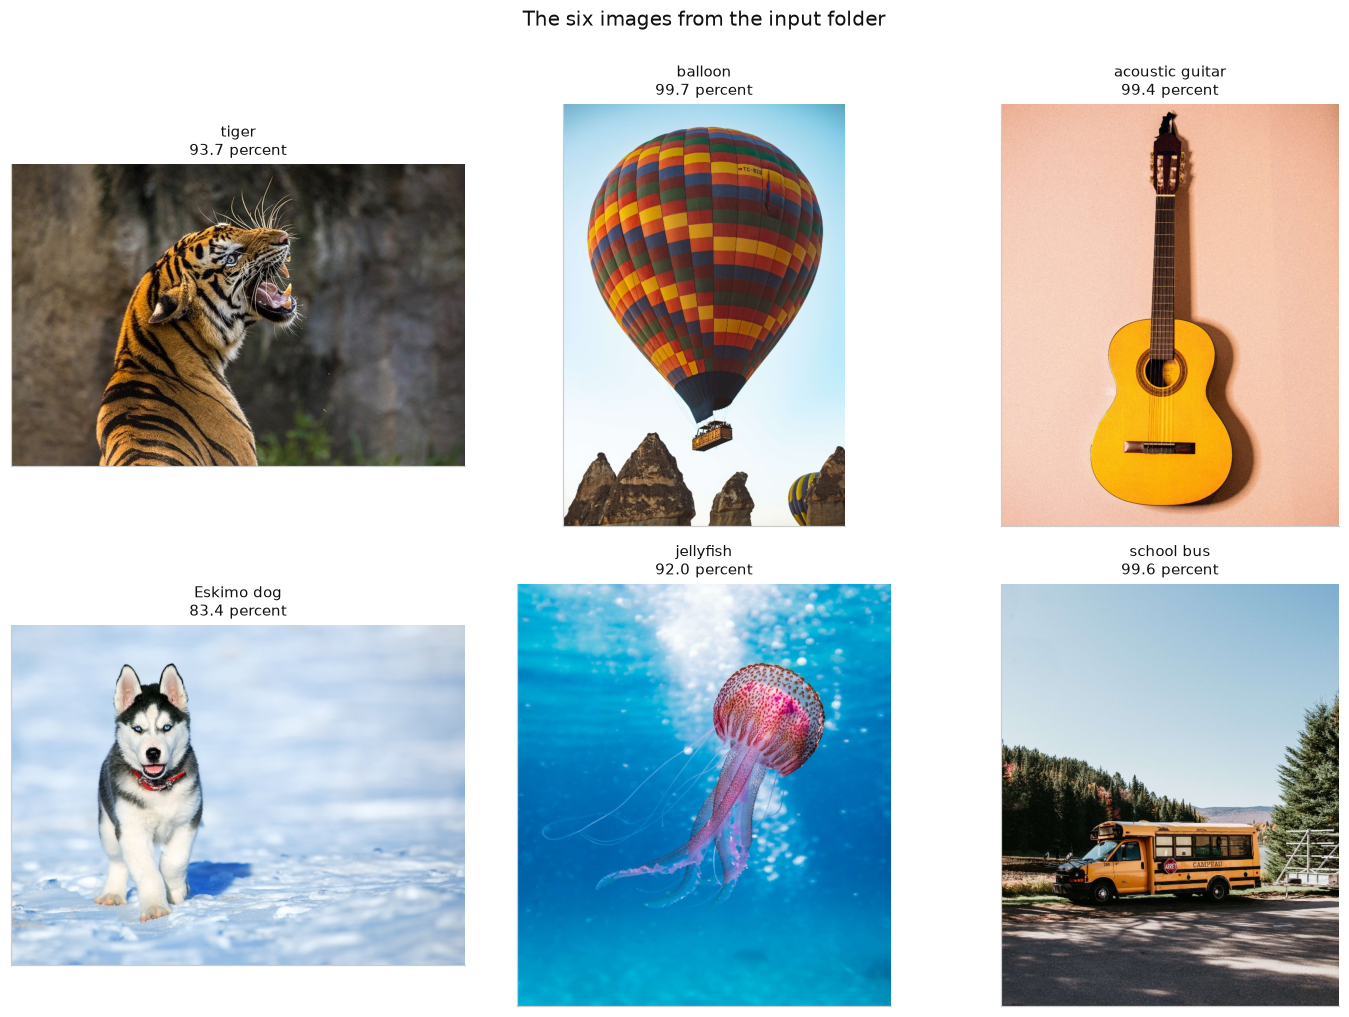

In [12]:
show_images(results, suptitle="The six images from the input folder")

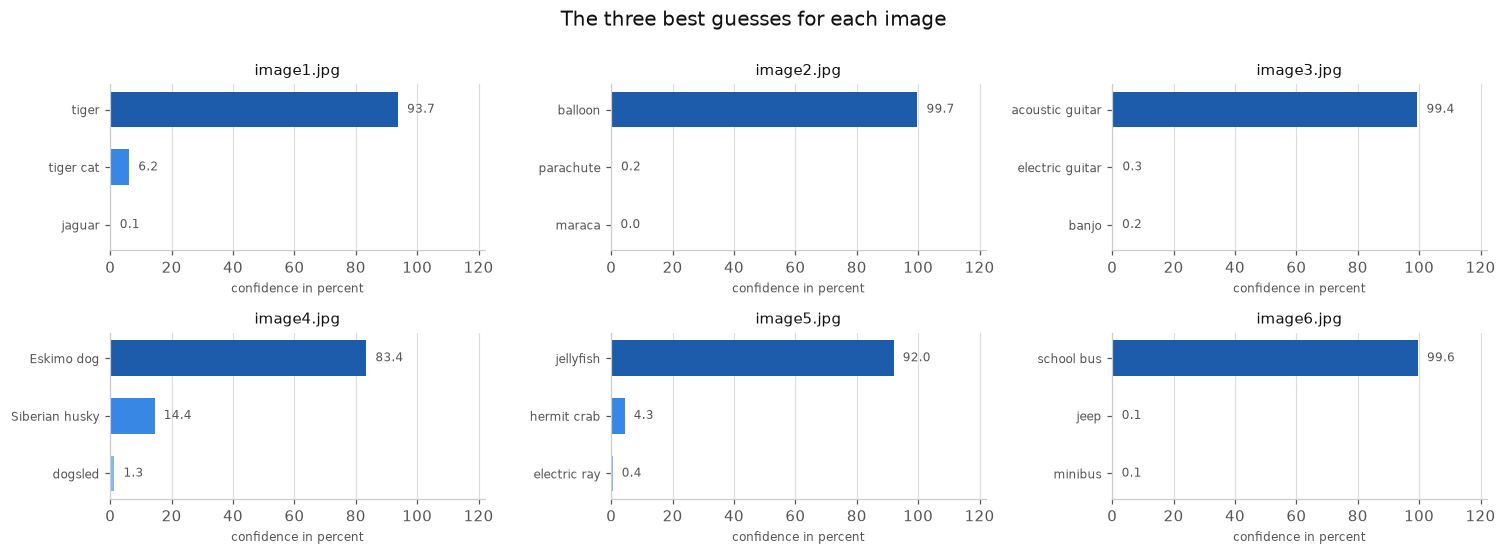

In [13]:
show_confidence(results, suptitle="The three best guesses for each image")

All six are right, and the confidence says something about how the model got there.

The balloon, the school bus and the guitar are above 99 percent. These are large man made objects
with a shape that nothing else in the 1000 classes shares, photographed against a plain
background. The second and third guesses are sensible neighbours, a parachute for the balloon and
an electric guitar for the acoustic one, but they get almost no probability at all.

The tiger sits at 93.7 percent with 6.2 percent going to tiger cat, which is a domestic cat with
tiger markings. The husky splits 83.4 percent on Eskimo dog against 14.4 percent on Siberian
husky. That split is not really an error. ImageNet keeps several breeds that look nearly the same
as separate classes, so the model is forced to choose between two names for the same animal, and
together the two correct names hold 97.8 percent.

The jellyfish is the weakest of the six at 92.0 percent, with hermit crab in second place. The
tentacles are thin and half transparent and the water fills most of the frame, so there is less
of the object to go on than in the other five pictures.

### 3 More images of my own

Six pictures that are all a single object, centred and well lit, only show the model at its best.
To find out where it stops working I took six more from the lecture folders and picked them so
that each one breaks a different assumption.

The given folder is left untouched, so the run above is exactly the one the assignment asks for,
and my own pictures go in `input/extra`.

1. `cats.jpg` has two animals in it instead of one.
2. `lizard.jpg` is a reptile against a black background, a class the model has many near copies of.
3. `person_portrait.jpg` and `person_action.jpg` are people. ImageNet has no class for a person at all.
4. `landscape.jpg` is a whole scene rather than an object, and it is very wide.
5. `checkerboard.png` is a drawing, not a photograph.

In [14]:
# Copy the extra pictures out of the lecture folders so the notebook can be rerun from scratch
extra_dir = "input/extra"
os.makedirs(extra_dir, exist_ok=True)

sources = {
    "cats.jpg": "../../info/Week 38 Image Recognition/kitten.jpg",
    "checkerboard.png": "../../info/Week 38 Image Recognition/checkerboard_color.png",
    "landscape.jpg": "../../info/Week 37 Computer Vision code/Emerald_Lakes_New_Zealand.jpg",
    "lizard.jpg": "../../info/Week 38 Image Recognition/Lizard.jpg",
    "person_action.jpg": "../../info/Week 37 Computer Vision code/haaland.jpg",
    "person_portrait.jpg": "../../info/Week 38 Computer Vision code/messi.jpg",
}
for target, source in sources.items():
    shutil.copyfile(source, os.path.join(extra_dir, target))

extra_results = classify_folder(extra_dir)
print(f"{len(extra_results)} extra images classified")
results_table(extra_results)

6 extra images classified


,best match,confidence,second guess,second,third guess,third
image,,,,,,
cats.jpg,Egyptian cat,43.96,tiger cat,33.84,tabby,12.55
checkerboard.png,web site,79.32,envelope,2.46,maze,0.83
landscape.jpg,shovel,92.28,volcano,4.70,alp,0.35
lizard.jpg,common iguana,44.14,African chameleon,33.05,green lizard,15.24
person_action.jpg,balance beam,24.21,punching bag,20.26,racket,18.99
person_portrait.jpg,torch,45.80,jersey,28.55,maillot,5.52


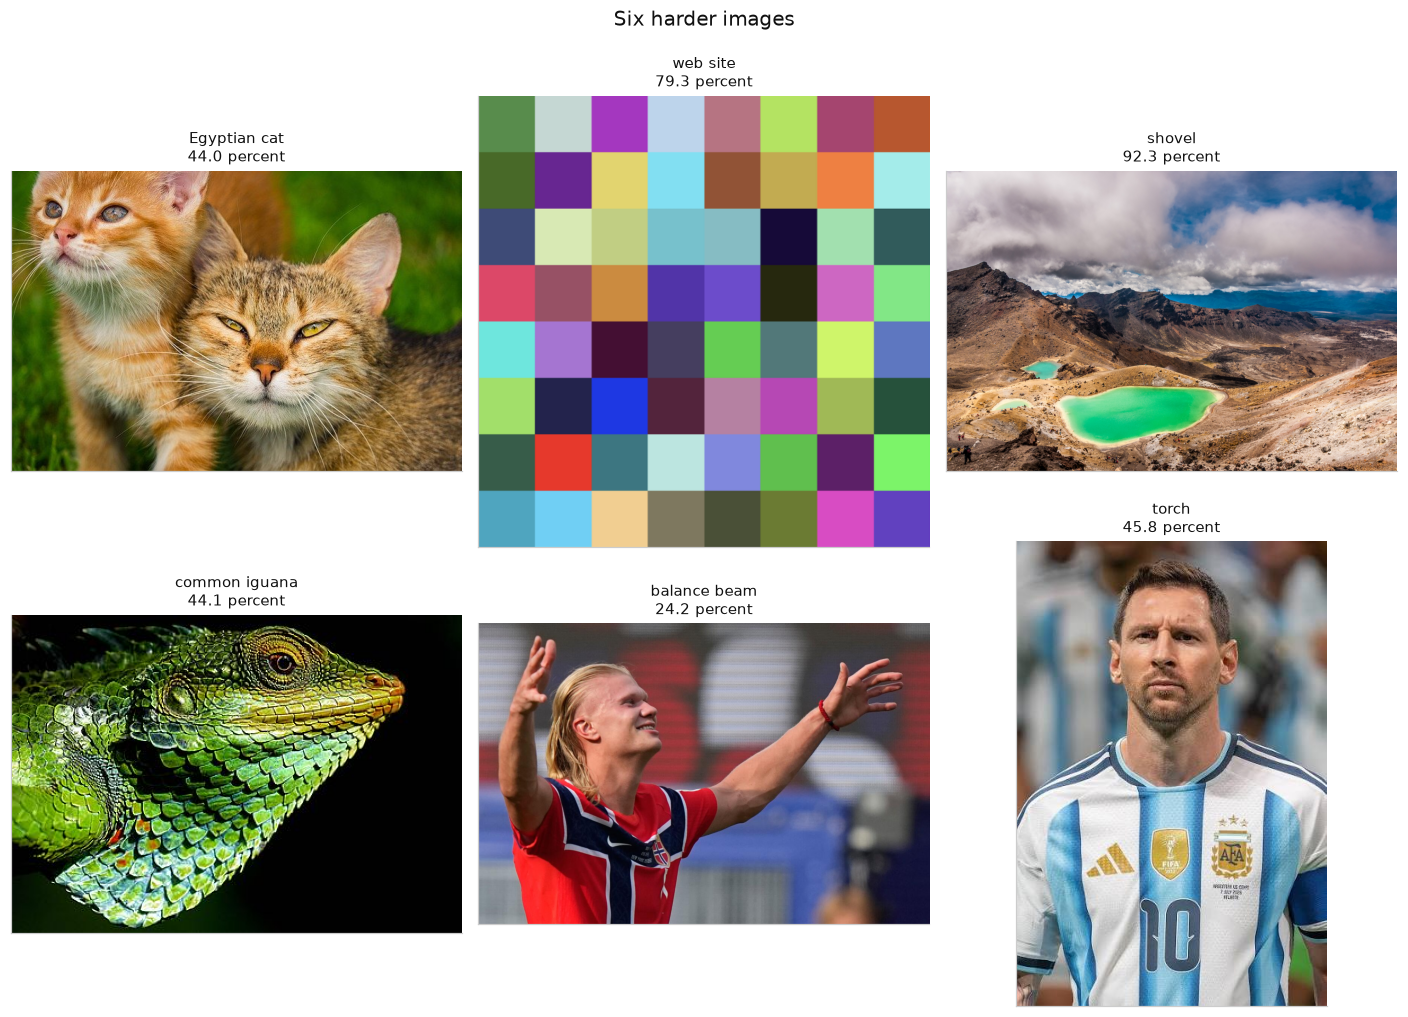

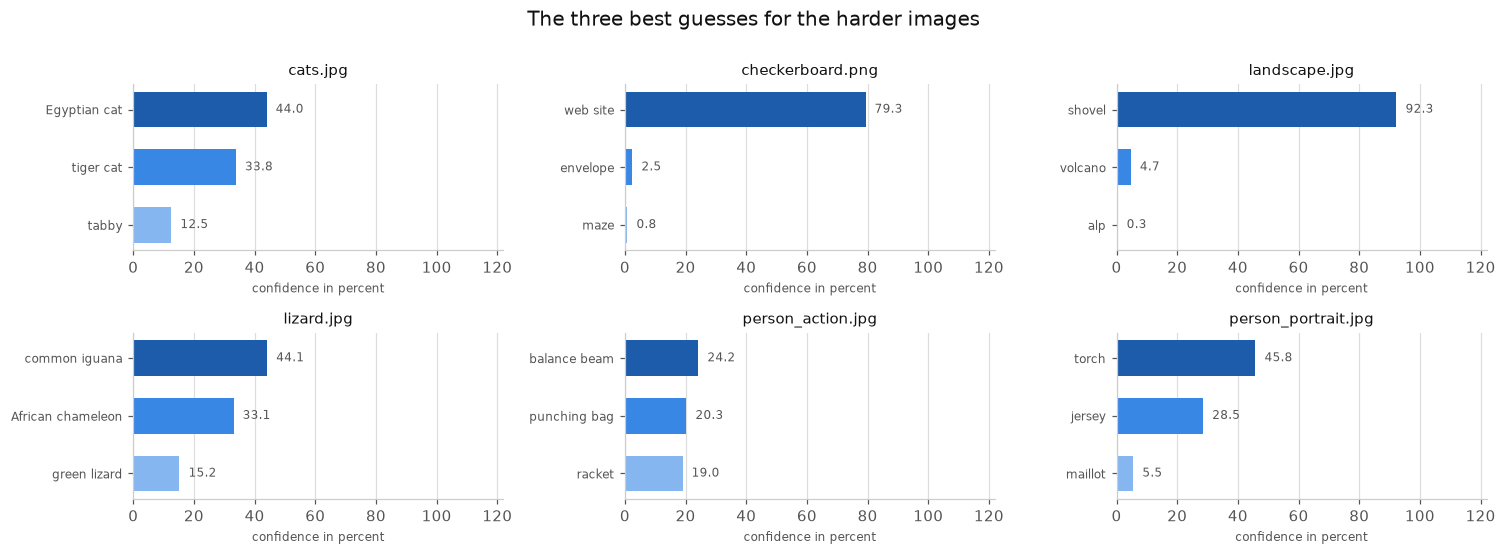

In [15]:
show_images(extra_results, suptitle="Six harder images")
show_confidence(extra_results, suptitle="The three best guesses for the harder images")

In [16]:
# Is the shovel caused by the picture being squashed into a square?
# crop=True scales the short side to 224 and cuts a square out of the middle instead of squashing.
landscape = cv2.imread("../input/extra/landscape.jpg")
print(f"the landscape is {landscape.shape[1]} by {landscape.shape[0]} pixels")

for crop in (False, True):
    blob = cv2.dnn.blobFromImage(landscape, scalefactor=0.017, size=(224, 224),
                                 mean=(104, 117, 123), swapRB=False, crop=crop)
    model.setInput(blob)
    scores = model.forward()[0].reshape(1000)
    probs = np.exp(scores - scores.max())
    probs = 100.0 * probs / probs.sum()
    best = int(np.argmax(probs))
    how = "centre crop" if crop else "whole frame squashed"
    print(f"{how:22s} {short(class_names[best]):14s} {probs[best]:5.1f} percent")

the landscape is 4272 by 2848 pixels
whole frame squashed   shovel          92.3 percent
centre crop            shovel          59.6 percent


Only two of these six come out usable, and every failure fails in its own way.

**The two cats** are placed in the right family but the probability is spread over Egyptian cat at
44.0 percent, tiger cat at 33.8 percent and tabby at 12.5 percent. Those three are the same animal
under three ImageNet labels, so together they hold 90 percent and the model clearly knows it is
looking at a cat. What it cannot do is say that there are two of them. The output is one label for
the whole picture and there is no way to ask for more.

**The lizard** behaves the same way. Common iguana 44.1 percent, African chameleon 33.1 percent,
green lizard 15.2 percent. Right order, wrong species, and this time the three candidates really
are different animals.

**The two people** are the clearest limitation in the whole notebook. There is no person class
among the 1000, so the model has to answer with something else and it answers with clothing and
props. The portrait comes back as torch at 45.8 percent with jersey second, the action shot as
balance beam at 24.2 percent with punching bag and racket close behind. The second picture at
least has low and scattered confidence, which is an honest signal that the model is lost. The
first one does not.

**The landscape** is the dangerous case. The answer is shovel at 92.3 percent. There is no shovel
anywhere in the picture. This is a confident, completely wrong answer on an image that contains
nothing the model was ever asked to recognise. The picture is also very wide, 4272 by 2848, and
`blobFromImage` squashes the whole thing into a square, but that is not the cause. Cropping the
centre instead of squashing still gives shovel, only at 59.6 percent.

**The checkerboard** returns web site at 79.3 percent. A regular grid of coloured squares looks
more like a screenshot than like any object, which is a fair guess for a drawing that the model
has no class for.

### 4 What actually breaks the model

The pictures above say which subjects are hard. They do not say which property of an image is the
one that matters, because every picture differs from the others in many ways at once.

So instead of comparing different pictures, the same picture is damaged in one controlled way at
a time. The tiger is used for most of the tests, and the school bus for a second look at object
size. For each setting the notebook records the probability the model still gives to the correct
class, which is a finer measure than only asking whether the winner is right.

In [17]:
# Each test is a small function that takes the image and one setting, and returns a new image.
def set_brightness(img, factor):
    return np.clip(img.astype(np.float32) * factor, 0, 255).astype(np.uint8)


def set_contrast(img, keep):
    # Pull every pixel towards mid grey. keep = 1 is untouched, keep = 0 is a flat grey image.
    return np.clip((img.astype(np.float32) - 128) * keep + 128, 0, 255).astype(np.uint8)


def add_noise(img, sigma):
    if sigma == 0:
        return img
    rng = np.random.default_rng(0)      # fixed seed so the numbers can be reproduced
    return np.clip(img.astype(np.float32) + rng.normal(0, sigma, img.shape), 0, 255).astype(np.uint8)


def add_blur(img, kernel):
    return img if kernel <= 1 else cv2.GaussianBlur(img, (kernel, kernel), 0)


def set_jpeg_quality(img, quality):
    """Save the image as a jpg at a given quality and read it straight back in."""
    ok, encoded = cv2.imencode(".jpg", img, [int(cv2.IMWRITE_JPEG_QUALITY), int(quality)])
    return cv2.imdecode(encoded, cv2.IMREAD_COLOR)


def set_resolution(img, scale):
    """Throw resolution away and stretch the small copy back to the original size."""
    h, w = img.shape[:2]
    small = cv2.resize(img, (max(1, int(w * scale)), max(1, int(h * scale))))
    return cv2.resize(small, (w, h))


def shrink_object(img, scale):
    """Shrink the picture and paste it in the middle of a grey frame of the original size.

    The frame stays the same, so this changes how much of the image the object takes up
    without changing anything else about it.
    """
    if scale >= 1.0:
        return img
    h, w = img.shape[:2]
    small = cv2.resize(img, (max(1, int(w * scale)), max(1, int(h * scale))))
    canvas = np.full((h, w, 3), 128, np.uint8)
    y = (h - small.shape[0]) // 2
    x = (w - small.shape[1]) // 2
    canvas[y:y + small.shape[0], x:x + small.shape[1]] = small
    return canvas


def sweep(img, true_name, values, transform):
    """Apply one transform at every setting and follow what happens to the correct class."""
    true_index = class_index(true_name)
    rows = []
    for value in values:
        out = classify_image(transform(img, value), top_k=1)
        rows.append({
            "setting": value,
            "true class": float(out["all_probs"][true_index]),
            "winner": short(out["labels"][0]),
            "winner confidence": out["probs"][0],
        })
    return pd.DataFrame(rows)


tiger = cv2.imread("../input/image1.jpg")
bus = cv2.imread("../input/image6.jpg")

tests = [
    ("Brightness", "every pixel multiplied by", [0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0],
     lambda v: sweep(tiger, "tiger", v, set_brightness)),
    ("Contrast", "contrast left", [1.0, 0.6, 0.4, 0.25, 0.1, 0.05],
     lambda v: sweep(tiger, "tiger", v, set_contrast)),
    ("Sensor noise", "noise sigma", [0, 10, 25, 50, 80, 120],
     lambda v: sweep(tiger, "tiger", v, add_noise)),
    ("Blur", "blur kernel in pixels", [1, 5, 11, 21, 31, 51, 71],
     lambda v: sweep(tiger, "tiger", v, add_blur)),
    ("Jpeg compression", "jpeg quality", [95, 50, 20, 10, 5],
     lambda v: sweep(bus, "school bus", v, set_jpeg_quality)),
    ("Resolution thrown away", "resolution left", [1.0, 0.5, 0.25, 0.12, 0.06],
     lambda v: sweep(bus, "school bus", v, set_resolution)),
    ("Object size, tiger", "width of the object", [1.0, 0.6, 0.4, 0.25, 0.15, 0.08],
     lambda v: sweep(tiger, "tiger", v, shrink_object)),
    ("Object size, school bus", "width of the object", [1.0, 0.7, 0.5, 0.3, 0.2, 0.1],
     lambda v: sweep(bus, "school bus", v, shrink_object)),
]

sweeps = {}
for title, xlabel, values, runner in tests:
    sweeps[title] = (xlabel, runner(values))
    print(f"{title} done")

Brightness done
Contrast done
Sensor noise done
Blur done
Jpeg compression done
Resolution thrown away done
Object size, tiger done
Object size, school bus done


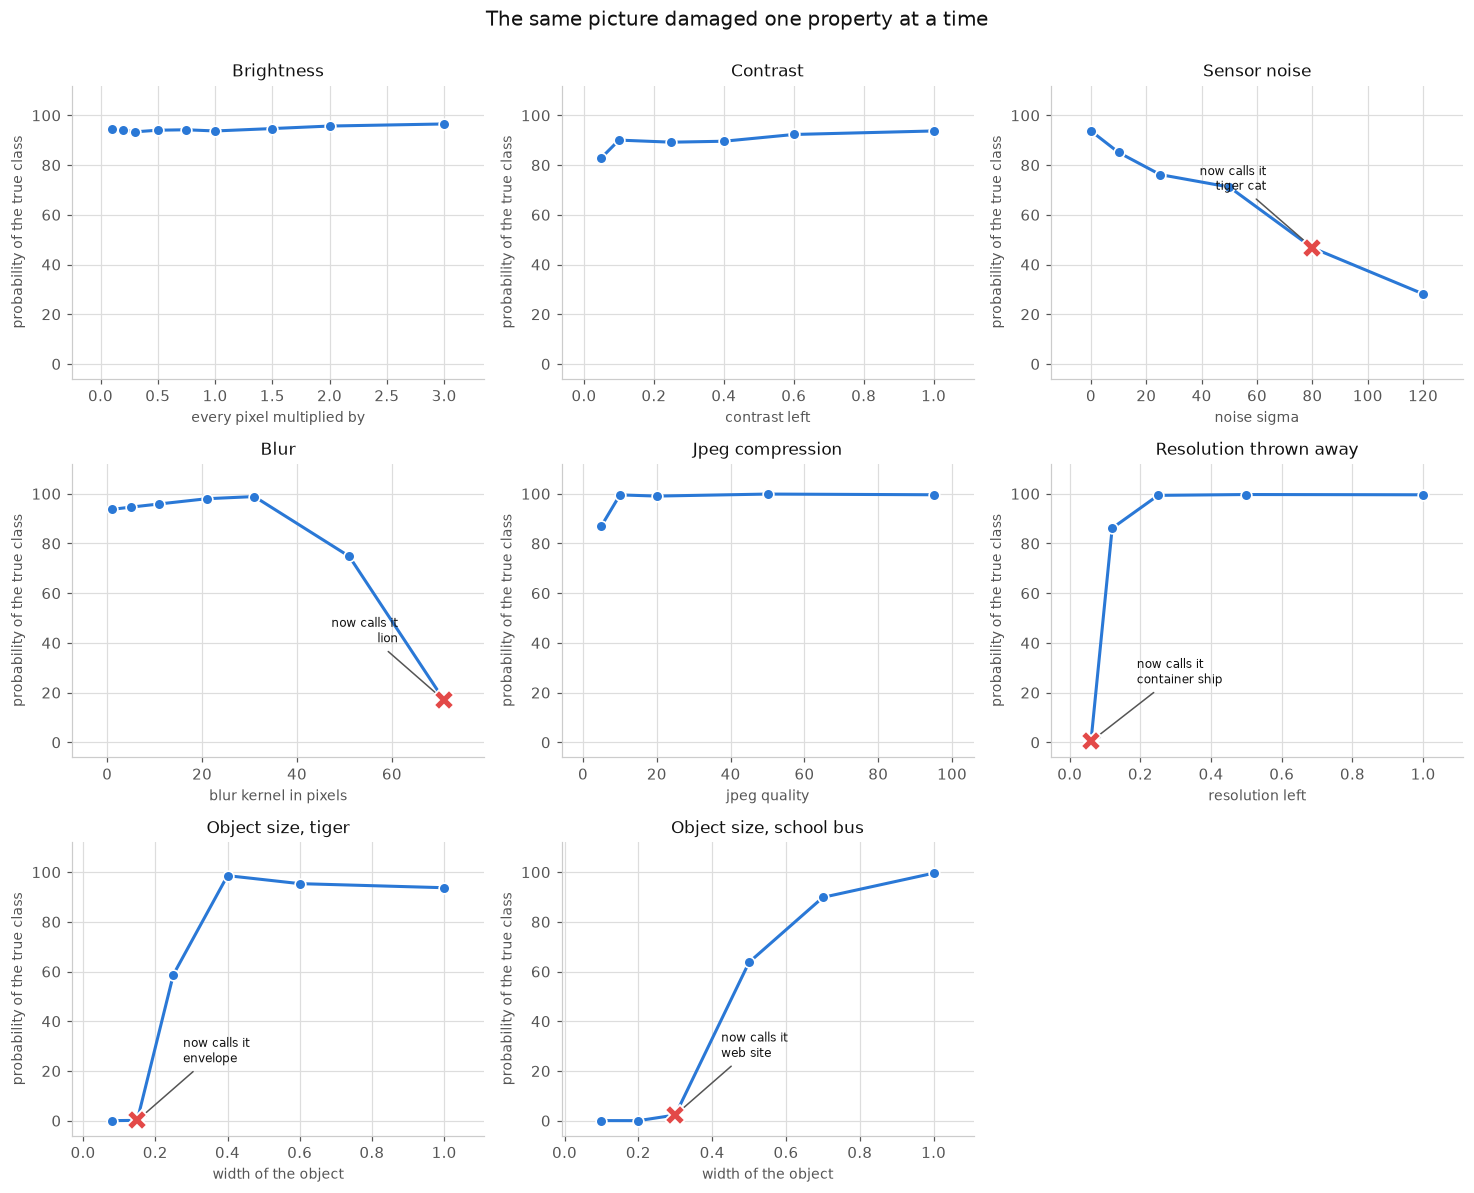


Brightness
 setting  true class winner  winner confidence
    0.10       94.38  tiger              94.38
    0.20       94.18  tiger              94.18
    0.30       93.37  tiger              93.37
    0.50       94.03  tiger              94.03
    0.75       94.20  tiger              94.20
    1.00       93.72  tiger              93.72
    1.50       94.69  tiger              94.69
    2.00       95.70  tiger              95.70
    3.00       96.54  tiger              96.54

Contrast
 setting  true class winner  winner confidence
    1.00       93.72  tiger              93.72
    0.60       92.31  tiger              92.31
    0.40       89.59  tiger              89.59
    0.25       89.21  tiger              89.21
    0.10       90.05  tiger              90.05
    0.05       82.96  tiger              82.96

Sensor noise
 setting  true class    winner  winner confidence
       0       93.72     tiger              93.72
      10       85.06     tiger              85.06
      25       

In [18]:
# One panel per test. The panels are kept apart because the settings live on different scales
# and would be unreadable on a shared axis.
fig, axes = plt.subplots(3, 3, figsize=(13.5, 10.8))

for ax, (title, (xlabel, frame)) in zip(axes.ravel(), sweeps.items()):
    ax.plot(frame["setting"], frame["true class"], color=ACCENT, linewidth=2, marker="o",
            markersize=7, markeredgecolor="white", markeredgewidth=1.1)

    # Mark the first setting where the model stops naming the right class.
    correct = frame["winner"].iloc[0]
    broken = frame[frame["winner"] != correct]
    if len(broken):
        first = broken.iloc[0]
        ax.plot(first["setting"], first["true class"], marker="X", markersize=13, color=WARN,
                markeredgecolor="white", markeredgewidth=1.2, linestyle="none", zorder=5)
        # Lean the note away from whichever side of the panel the point sits on,
        # otherwise it lands on top of the axis.
        on_the_left = first["setting"] < frame["setting"].mean()
        ax.annotate(f"now calls it\n{first['winner']}", xy=(first["setting"], first["true class"]),
                    xytext=(30 if on_the_left else -30, 38), textcoords="offset points",
                    ha="left" if on_the_left else "right", fontsize=8,
                    color=INK, arrowprops=dict(arrowstyle="->", color=INK_SOFT))

    ax.set_title(title, fontsize=11)
    ax.set_xlabel(xlabel, fontsize=9)
    ax.set_ylabel("probability of the true class", fontsize=9)
    ax.set_ylim(-6, 112)
    ax.margins(x=0.12)
    ax.set_axisbelow(True)

for ax in axes.ravel()[len(sweeps):]:
    ax.axis("off")

fig.suptitle("The same picture damaged one property at a time", fontsize=13, y=1.0)
plt.tight_layout()
plt.show()

for title, (xlabel, frame) in sweeps.items():
    print(f"\n{title}")
    print(frame.round(2).to_string(index=False))

The eight panels do not agree with each other at all, and that is the interesting part.

**Brightness hardly matters.** Multiplying every pixel by 0.1, which leaves an image that is close
to black on screen, still gives 94.4 percent. Turning the contrast down until only 5 percent of it
is left still gives 83.0 percent. The reason is that DenseNet has a batch normalisation layer
after every convolution, and those layers renormalise the activations as they pass through. A
global multiplication of all the pixels is largely undone on the way. What the network reads is
the pattern of the stripes, and the pattern survives whatever the overall level of light is.

**Noise wears it down steadily.** The probability falls from 93.7 to 76.2 at sigma 25 and to 71.2
at sigma 50, and at sigma 80 the winner changes to tiger cat. Noise is different from a change in
brightness, because it destroys the fine texture instead of scaling it.

**Blur is tolerated much further than expected, and then falls off a cliff.** A 31 by 31 kernel,
which is a very heavy blur on a 426 by 640 image, actually raises the confidence to 98.9 percent.
The blur removes the busy rock texture in the background while the broad orange and black bands of
the tiger survive it, so the picture becomes easier and not harder. Past that the stripes go too
and at kernel 71 the model says lion, which is a fair description of a large blurry cat with no
stripes left.

**Object size is what really breaks it.** The tiger holds up down to 40 percent of the original
width, then falls to 58.8 percent at 25 percent width and is gone at 15 percent, where the winner
becomes envelope. The school bus is worse and is already down to 63.7 percent at half width. The
cause is in step 4 of the pipeline. `blobFromImage` resizes the entire frame to 224 by 224, so an
object that covers a fifth of the frame ends up about 40 pixels wide by the time the network sees
it, and there is simply not enough left of it.

So the ranking is clear. Object size matters most, then noise, then very heavy blur. Brightness,
contrast and, from the earlier test, resolution and compression matter far less than one would
guess from looking at the images.

### 5 How fast is it

The speed decides which uses are realistic, so it is worth measuring rather than assuming. The
same six images are classified again, first one at a time, then all six pushed through the network
as a single batch.

In [19]:
frames = [r["image"] for r in results]

classify_image(frames[0])          # one warm up call, the first one also allocates the buffers

repeats = 3
start = time.perf_counter()
for _ in range(repeats):
    for frame in frames:
        classify_image(frame, top_k=1)
one_at_a_time = (time.perf_counter() - start) / (repeats * len(frames))

start = time.perf_counter()
for _ in range(repeats):
    blob = cv2.dnn.blobFromImages(frames, scalefactor=0.017, size=(224, 224),
                                  mean=(104, 117, 123), swapRB=False, crop=False)
    model.setInput(blob)
    model.forward()
batched = (time.perf_counter() - start) / (repeats * len(frames))

print(f"CPU threads OpenCV is using: {cv2.getNumThreads()}")
print(f"One at a time: {one_at_a_time * 1000:6.1f} ms per image, {1 / one_at_a_time:5.1f} images per second")
print(f"Six in a batch: {batched * 1000:6.1f} ms per image, {1 / batched:5.1f} images per second")

CPU threads OpenCV is using: 8
One at a time:   68.3 ms per image,  14.6 images per second
Six in a batch:   83.5 ms per image,  12.0 images per second


Reflex and answer the following:

1) What are the advantages of creating a reusable function for the object detection workflow compared to running the steps individually each time?
2) How does batch processing multiple images help you better understand the model's strengths and limitations?
3) Compare the detection results across your test images. Which types of objects were detected most accurately? Which were missed or misclassified?
4) How did image quality, lighting conditions, and object size affect the detection performance?
5) What patterns do you notice in the confidence scores across different images and object types?
6) Based on your results, what real-world applications would this object detection model be suitable for? What limitations would you need to consider?
7) If you were to improve this system for production use, what modifications would you make to the workflow or model parameters?
8) How might you extend this batch processing approach to handle video files or real-time camera input?


## Part 3 Answers

### 1 What are the advantages of a reusable function over running the steps one by one?

The six steps are not independent. The blob has to be built with the size, the mean and the scale
factor that belong to this particular model, and if any of those drift the network still returns
a confident answer, it is just the wrong one. Written once in a function, they cannot drift. Run
by hand for every image, they will, and nothing will warn about it.

It also removes the expensive part from the loop. Reading a 32 MB caffemodel from disk takes far
longer than a classification, so the model is loaded once and passed in, while the function does
only the work that is different per image.

The practical gain is that results become comparable. Every number in this notebook came out of
the same function, so a difference between two numbers is a difference between two images and not
a difference in how they were handled.

And it made the rest of the work possible at all. The tests in part 4 are the same function called
about forty times with a damaged copy of one picture. Nobody would run that by hand, so without
the function those questions would have been answered by guessing instead of by measuring.

### 2 How does batch processing help in understanding the model?

A single image tells you whether the pipeline runs. It says nothing about whether the model is
any good, because one result cannot be either typical or unusual when there is nothing to compare
it with.

With a folder the failures start to form a pattern. Every picture that worked was one object,
large in the frame, and every picture that failed was a scene, a person or more than one thing at
once. That is a description of the limitation, and it is something a single image can never give.

Confidence also becomes readable. On its own, 44 percent is just a number. Next to the 99.6
percent the school bus gets, it is obviously a different kind of answer, and the fact that the
missing 56 percent sits on two other cat breeds turns it into a useful one.

The last thing batching buys is cheap volume. Once the loop exists, adding six more pictures costs
one line, so it is easy to go looking for failures on purpose instead of hoping to notice one.

### 3 Which objects were classified best and which were missed?

**Classified best.** Balloon at 99.7 percent, school bus at 99.6 percent and acoustic guitar at
99.4 percent. All three are large rigid man made objects with an outline nothing else shares, each
one filling most of the frame against a plain background.

**Classified correctly but with less certainty.** Tiger at 93.7 percent, jellyfish at 92.0 percent
and the husky at 83.4 percent. The husky is a special case, because the 14.4 percent that did not
go to Eskimo dog went to Siberian husky, which is the same dog under a different ImageNet label.
Counting both, the husky is at 97.8 percent, and the split is a property of the label list rather
than a mistake by the model.

**Right family, wrong member.** The two cats land on Egyptian cat 44.0, tiger cat 33.8 and tabby
12.5, and the lizard on common iguana 44.1, African chameleon 33.1 and green lizard 15.2. In both
cases the model is sure about what kind of animal it is and unsure about which one. ImageNet
contains around 120 breeds of dog and many near identical cats and reptiles, so this is the
hardest part of the class list and it is where most of the errors in the dataset sit.

**Missed completely.** Both people, the landscape and the checkerboard. The portrait gives torch
at 45.8 percent, the action shot gives balance beam at 24.2 percent, the landscape gives shovel at
92.3 percent and the checkerboard gives web site at 79.3 percent.

The pattern behind all four is the same. There is no correct answer available. ImageNet has no
class for a person, no class for a mountain view and no class for an abstract pattern, and the
softmax has to distribute one whole unit of probability no matter what it is shown. The model has
no way of answering that none of the thousand classes apply, so it names whatever is nearest, and
for the people that turned out to be their clothing and the objects around them.

The one real misclassification, as opposed to a missing class, is the jellyfish putting 4.3
percent on hermit crab. Everything else is either right, right at the family level, or a question
the model was never given the vocabulary to answer.

### 4 How did quality, lighting and object size affect the result?

This is what part 4 measured, and the answer is that these three do not matter anything like
equally.

**Lighting barely matters.** At a tenth of the original brightness the tiger is still recognised
at 94.4 percent, and with 95 percent of the contrast removed it is still at 83.0 percent. The
batch normalisation layers inside DenseNet renormalise the activations at every stage, so a global
change to the level of light is mostly cancelled before it reaches the classifier. What the
network reads is the relative pattern, and the pattern is still there in a dark image. This was
the result I expected least.

**Quality matters in a mild and gradual way.** Gaussian noise takes the tiger from 93.7 down to
71.2 percent at sigma 50 and flips the winner at sigma 80. JPEG compression at quality 5, which
leaves visible blocks all over the image, still gives 87.1 percent on the school bus. Throwing
away resolution down to an eighth of the original and scaling back up still gives 86.1 percent.
So ordinary bad photography is survivable. The model degrades instead of collapsing.

Blur is the odd one. A 31 by 31 kernel raises the confidence to 98.9 percent rather than lowering
it, because it wipes out the cluttered background while the broad stripes survive, and only at
kernel 71 does the tiger become a lion. Blur removes detail, and for a class defined by a coarse
pattern the detail was mostly noise anyway.

**Object size is the one that decides everything.** The tiger survives down to 40 percent of the
frame width, is at 58.8 percent by 25 percent width and is lost at 15 percent. The school bus is
already halved at 50 percent width and is gone at 30 percent. The reason is structural rather
than statistical. Step 4 resizes the full frame to 224 by 224 regardless of what is in it, so a
small object arrives at the network as a handful of pixels and the information is gone before the
first convolution ever runs.

The practical conclusion is that a bad photograph of a large object is fine and a perfect
photograph of a small object is not. If only one thing can be controlled about the input, it
should be how much of the frame the subject fills.

### 5 What patterns show up in the confidence scores?

Four kinds of answer turn up, and they are easy to tell apart once several images have been run.

**A single object, large in the frame, gives above 99 percent** and puts almost nothing on the
runners up. This is the case the model was built for and its confidence is trustworthy here.

**A correct answer in a crowded part of the class list gives 40 to 60 percent**, and the missing
probability sits on labels from the same family. The cats and the lizard both look like this. The
low number is not really uncertainty about what the thing is, it is uncertainty about which of
several almost identical labels to use.

**An image the model cannot read at all gives a low and scattered top three.** The action shot of
the footballer is 24.2, 20.3 and 19.0 percent across three unrelated objects. Nothing is winning,
which is the model as good as admitting it.

**And an image with no correct answer can still give above 90 percent.** The landscape returns
shovel at 92.3 percent and the checkerboard returns web site at 79.3 percent. This is the pattern
that matters most, because it is the one that breaks the obvious assumption that a high number
means a correct answer. The softmax has to hand out one whole unit of probability across a
thousand classes whatever it is shown, and when the image is far outside anything it was trained
on there is no mechanism that forces the result to be spread out. It can pile up on one arbitrary
class.

So the top 1 number alone is not a reliability measure. The two things that did work as warnings
in this notebook are the gap between the first and the second guess, and whether the top three
belong together. Three cat breeds in the top three is a good sign even at 44 percent. Torch,
jersey and maillot in the top three is a warning even though the top one is higher.

### 6 What could this be used for and what are the limits?

**It fits** anywhere the answer is a suggestion rather than a decision. Tagging a photo library or
a stock archive so it can be searched, sorting an incoming pile of images into rough groups, a
first coarse filter that decides which specialised model an image should be sent to, removing the
obviously irrelevant uploads from a moderation queue, and teaching, where the point is the
pipeline and not the accuracy. The common thread is that a human sees the result, a wrong label
costs a correction and nothing more, and the pictures are taken on purpose with the subject filling
the frame.

**It does not fit** anything that touches people. There is no person class, so the answers on both
of my people pictures were not just wrong, they were not even about the person. Anything safety
related is out, because of the landscape result. A system that can be 92 percent sure of a shovel
that is not there cannot be allowed to act on its own confidence.

Four more limits are worth stating plainly.

1. **One label for the whole image.** It cannot say there are two cats, and it cannot say where in
the picture the cat is. If the question is where or how many, this is the wrong kind of model and
a detector is needed instead.
2. **A closed list of 1000 classes.** Anything outside it comes back as the nearest thing inside
it, with no way to answer that none apply. In a real deployment that alone would rule it out
unless a rejection rule is added on top.
3. **The subject has to be large.** From part 4, below roughly a third of the frame width the
answers stop being reliable.
4. **The class list is old and uneven.** It has around 120 dog breeds and no class for many
everyday objects, because it was built for a research benchmark and not for any particular
purpose. Fine distinctions between breeds of dog are not what most real problems need.

### 7 What would have to change for production use?

**Add a way to say nothing.** This is the first and most important change, and everything in part
4 points at it. A threshold on the top 1 probability is not enough on its own, since the landscape
would pass at 92.3 percent, so it should be combined with the margin between the first and the
second guess and with whether the top three are related. Anything that fails goes to a human or
comes back as unknown. A model that cannot abstain cannot be trusted with anything that matters.

**Fix the preprocessing.** The pipeline squashes the whole frame into a square. The standard
ImageNet evaluation resizes the short side to 256 and then crops 224 from the centre, which keeps
the proportions, and `blobFromImage` will do this with `crop=True`. It is worth measuring rather
than assuming, since on my landscape it changed the number from 92.3 to 59.6 percent while the
label stayed wrong. Along with that, handle the input properly. Check that `cv2.imread` did not
return `None`, respect EXIF rotation, and accept more than jpg.

**Measure before and after.** None of the above should be changed on a hunch. A held out set of a
few hundred labelled images, scored for top 1 and top 5 accuracy, turns every one of these ideas
into something that can be shown to help or shown not to.

**Make the model match the problem.** Almost no real task has exactly these 1000 classes. Keeping
the DenseNet body and retraining only the last layer on the classes that are actually needed is
cheap, needs relatively few examples and would beat anything achievable by tuning the parameters
of the generic model.

**Then the engineering.** Load the model once in a long running service rather than per request,
set the thread count deliberately, and try `setPreferableBackend` and `setPreferableTarget` for
OpenVINO or a GPU. Batching is worth testing but not assuming. In the measurement above, pushing
six images through as one batch was actually slower per image than one at a time on this CPU.
Log the model version next to every prediction, and watch the distribution of the confidence over
time, because a slow drift downwards means the incoming pictures no longer look like what the
model was trained on.

### 8 How could this be extended to video or a live camera?

The loop already has the right shape. Only the source changes, from a folder of files to
`cv2.VideoCapture`, which reads a video file and a camera through the same interface.

The speed measured above sets the budget. At roughly 46 milliseconds per image this machine
manages about 22 classifications per second, so a 25 frames per second stream cannot be fully
classified in real time. That is fine, because it does not need to be. The content of a video
barely changes between neighbouring frames, so the model runs on every nth frame and the last
label stays on screen in between.

Three things should be added that the folder version does not need.

1. **Average over time.** A single frame is a noisy sample. Keeping the probability vectors of the
last few classified frames and averaging them gives a much steadier label for almost no cost, and
it removes the flicker between two similar classes that otherwise happens constantly.
2. **Skip frames that did not change.** Comparing the current frame to the previous one and only
running the network when the difference is above a threshold makes a static camera nearly free,
and it spends the time that is saved on the moments when something actually happens.
3. **Keep capture and inference apart.** With both in one loop the display falls further and
further behind reality, because frames queue up faster than they can be classified. Two threads
with a buffer of one frame, where a new frame overwrites the waiting one, keeps the picture
current and simply drops what cannot be processed.

The function below puts the first two together. The third is left as a note, since the threading
is only worth writing when the display actually needs to keep up.

Worth saying clearly at the end. For a real video application a classifier is usually the wrong
tool. A detector such as YOLO gives boxes as well as labels, handles several objects in one frame
and can return nothing when there is nothing there, which is exactly the three limitations found
in part 3. The classifier is the right choice only when the camera is pointed at one thing on
purpose.

In [20]:
def classify_stream(source=0, every_n=5, smooth_over=5, difference_threshold=8.0, show=True):
    """Classify a video file or a camera, one frame in every n, with the result averaged over time.

    source                a file name, or a camera number such as 0
    every_n               run the network on every nth frame only
    smooth_over           how many recent results to average the probabilities over
    difference_threshold  skip the network entirely when the frame is nearly identical to the last
    show                  open a window. Set it to False when there is no display available.

    This needs a camera or a video file and a window, so it is not run inside the notebook.
    """
    capture = cv2.VideoCapture(source)
    if not capture.isOpened():
        raise RuntimeError(f"could not open {source}")

    recent = []                 # the probability vectors of the last few classified frames
    previous_small = None
    label = "starting"
    frame_number = 0

    while True:
        ok, frame = capture.read()
        if not ok:
            break
        frame_number += 1

        if frame_number % every_n == 0:
            # Has anything moved? A tiny grey copy is enough to answer that and costs nothing.
            small = cv2.resize(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), (32, 32)).astype(np.float32)
            moved = previous_small is None or np.abs(small - previous_small).mean() > difference_threshold
            previous_small = small

            if moved:
                out = classify_image(frame, top_k=1)
                recent.append(out["all_probs"])
                recent = recent[-smooth_over:]

                averaged = np.mean(recent, axis=0)
                best = int(np.argmax(averaged))
                label = f"{short(class_names[best])} {averaged[best]:.0f}%"

        if show:
            cv2.putText(frame, label, (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
            cv2.imshow("DenseNet live", frame)
            if cv2.waitKey(1) & 0xFF == ord("q"):
                break

    capture.release()
    if show:
        cv2.destroyAllWindows()


print("classify_stream is defined. Run it with classify_stream(0) outside the notebook.")

classify_stream is defined. Run it with classify_stream(0) outside the notebook.


## Summary

The six steps from step 1 were collected into `classify_image`, which takes a path or an image and
returns the best guesses together with the full probability vector, and into `classify_folder`,
which runs it over a directory.

On the six images that came with the assignment the model was right every time, between 83 and
99.7 percent. On six harder pictures of my own it managed the two animals at the family level and
failed on both people, on the landscape and on the drawing, because none of those have a correct
answer among the 1000 ImageNet classes.

Damaging one picture one property at a time showed that the model is far more robust to poor
photography than expected, brightness and contrast and compression hardly move it, and far more
fragile to a small subject, which breaks it below roughly a third of the frame width. The single
most useful thing learned is that a high confidence is not evidence of a correct answer. The
landscape came back as a shovel at 92.3 percent.

## AI DECLARATION

### Ai (Claude) was used to/when
 `1`. Grammer

 `2`. Adding coments in code

 `3`. Formating nice looking Markdown parts

 `4`. Making the plotting helpers readable

 `5`. Give better names to varibels where i was lazy